# Exercise 10 - Generate Bach-like chorales

In [35]:
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
from pathlib import Path
import pathlib
import tarfile
import matplotlib.pyplot as plt

In [30]:
data_dir = (
    Path.home()
    / ".keras"
    / "datasets"
    / "jsb_chorales"
    / "jsb_chorales"
)

WINDOW_SIZE = 32
EMBEDDING_DIM = 32
GRU_UNITS = 128
BATCH_SIZE = 32
EPOCHS = 30

In [31]:
def load_chorales(split):
    folder = data_dir / split
    files = sorted(folder.glob("*.csv"))
    if not files:
        raise FileNotFoundError(f"No CSV files found in: {folder}")

    return [pd.read_csv(file).to_numpy(dtype=np.int32) for file in files]

train_chorales = load_chorales("train")
valid_chorales = load_chorales("valid")
test_chorales = load_chorales("test")

all_chorales = (train_chorales + valid_chorales + test_chorales)

if any(chorale.ndim != 2 or chorale.shape[1] != 4 for chorale in all_chorales):
    raise ValueError("Every chorale must contain exactly four voices.")
if any(chorale.min() < 0 for chorale in all_chorales):
    raise ValueError("Note IDs must be non-negative.")
NUM_NOTES = int(max(chorale.max() for chorale in all_chorales) + 1)

print("Dataset loaded")
print("Training chorales:", len(train_chorales))
print("Validation chorales:", len(valid_chorales))
print("Test chorales:", len(test_chorales))
print("Example chorale shape:", train_chorales[0].shape)
print("Number of note IDs:", NUM_NOTES)

Dataset loaded
Training chorales: 229
Validation chorales: 76
Test chorales: 77
Example chorale shape: (192, 4)
Number of note IDs: 82


In [32]:
def make_windows(chorales, window_size=WINDOW_SIZE):
    X, y = [], []
    for chorale in chorales:
        for start in range(len(chorale) - window_size):
            X.append(chorale[start:start + window_size])
            y.append(chorale[start + window_size])

    return (np.asarray(X, dtype=np.int32), np.asarray(y, dtype=np.int32))

X_train, y_train = make_windows(train_chorales)
X_valid, y_valid = make_windows(valid_chorales)
X_test, y_test = make_windows(test_chorales)

if len(X_train) == 0 or len(X_valid) == 0 or len(X_test) == 0:
    raise ValueError("One of the dataset splits produced no training windows.")

print("\nWindow shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


Window shapes:
X_train: (47900, 32, 4)
y_train: (47900, 4)
X_valid: (15976, 32, 4)
y_valid: (15976, 4)
X_test: (16436, 32, 4)
y_test: (16436, 4)


In [33]:
y_train_list = [y_train[:, i] for i in range(4)]
y_valid_list = [y_valid[:, i] for i in range(4)]
y_test_list = [y_test[:, i] for i in range(4)]

inputs = keras.Input(shape=(WINDOW_SIZE, 4), dtype="int32")
x = layers.Embedding(input_dim=NUM_NOTES, output_dim=EMBEDDING_DIM)(inputs)
x = layers.Reshape((WINDOW_SIZE, 4 * EMBEDDING_DIM))(x)
x = layers.GRU(GRU_UNITS)(x)
x = layers.Dense(128, activation="relu")(x)
outputs = [layers.Dense(NUM_NOTES, activation="softmax", name=f"voice_{i}")(x) for i in range(4)]
model = keras.Model(inputs=inputs, outputs=outputs)
model.summary()

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=["sparse_categorical_crossentropy", "sparse_categorical_crossentropy", "sparse_categorical_crossentropy", "sparse_categorical_crossentropy"],
    metrics=[["sparse_categorical_accuracy"], ["sparse_categorical_accuracy"], ["sparse_categorical_accuracy"], ["sparse_categorical_accuracy"]])

early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = model.fit(
    X_train,
    y_train_list,
    validation_data=(X_valid, y_valid_list),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping]
)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)    │ (None, 32, 4)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding_4 (Embedding)       │ (None, 32, 4, 32)         │           2,624 │ input_layer_5[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape_3 (Reshape)           │ (None, 32, 128)           │               0 │ embedding_4[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ gru_4 (GRU)                   │ (None, 128)               │          99,072 │ reshape_3[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_3 (Dense)               │ (None, 128)               │          16,512 │ gru_4[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ voice_0 (Dense)               │ (None, 82)                │          10,578 │ dense_3[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ voice_1 (Dense)               │ (None, 82)                │          10,578 │ dense_3[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ voice_2 (Dense)               │ (None, 82)                │          10,578 │ dense_3[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ voice_3 (Dense)               │ (None, 82)                │          10,578 │ dense_3[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 160,520 (627.03 KB)

 Trainable params: 160,520 (627.03 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
1497/1497 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - loss: 4.4856 - voice_0_loss: 0.9934 - voice_0_sparse_categorical_accuracy: 0.7461 - voice_1_loss: 1.0164 - voice_1_sparse_categorical_accuracy: 0.7347 - voice_2_loss: 1.1045 - voice_2_sparse_categorical_accuracy: 0.7178 - voice_3_loss: 1.3712 - voice_3_sparse_categorical_accuracy: 0.6530 - val_loss: 3.4489 - val_voice_0_loss: 0.7295 - val_voice_0_sparse_categorical_accuracy: 0.8094 - val_voice_1_loss: 0.8158 - val_voice_1_sparse_categorical_accuracy: 0.7855 - val_voice_2_loss: 0.8900 - val_voice_2_sparse_categorical_accuracy: 0.7732 - val_voice_3_loss: 1.0097 - val_voice_3_sparse_categorical_accuracy: 0.7247
Epoch 2/30
1497/1497 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - loss: 3.1368 - voice_0_loss: 0.6676 - voice_0_sparse_categorical_accuracy: 0.8134 - voice_1_loss: 0.7381 - voice_1_sparse_categorical_accuracy: 0.7937 - voice_2_loss: 0.8040 - voice_2_sparse_categorical_accuracy: 0.7799 - voice_3_loss: 0.9270 - voice_3_sparse_categori

In [34]:
print("\nTest evaluation:")
test_results = model.evaluate(X_test, y_test_list, return_dict=True)
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")


Test evaluation:
514/514 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 2.6382 - voice_0_loss: 0.5190 - voice_0_sparse_categorical_accuracy: 0.8439 - voice_1_loss: 0.6540 - voice_1_sparse_categorical_accuracy: 0.8081 - voice_2_loss: 0.7101 - voice_2_sparse_categorical_accuracy: 0.7909 - voice_3_loss: 0.7546 - voice_3_sparse_categorical_accuracy: 0.7827
loss: 2.6382
voice_0_loss: 0.5190
voice_0_sparse_categorical_accuracy: 0.8439
voice_1_loss: 0.6540
voice_1_sparse_categorical_accuracy: 0.8081
voice_2_loss: 0.7101
voice_2_sparse_categorical_accuracy: 0.7909
voice_3_loss: 0.7546
voice_3_sparse_categorical_accuracy: 0.7827


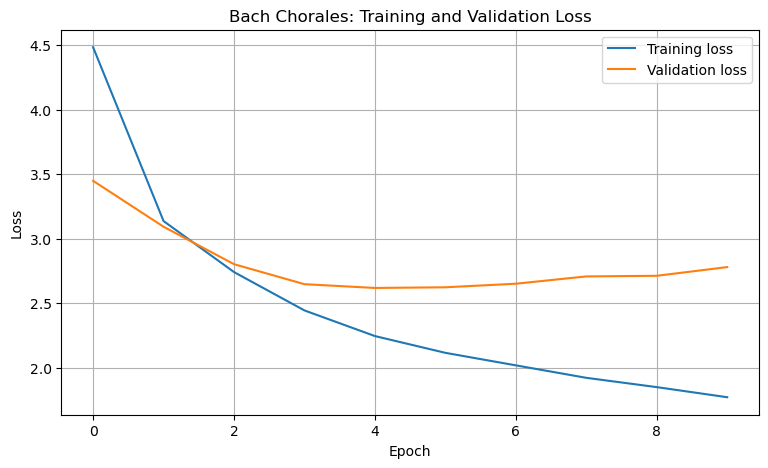

In [36]:
plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Bach Chorales: Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [39]:
def generate_chorale(model, seed, num_steps=100):
    generated = seed.copy()

    for _ in range(num_steps):
        model_input = generated[-WINDOW_SIZE:]
        model_input = np.expand_dims(model_input, axis=0)
        predictions = model.predict(model_input, verbose=0)
        next_notes = np.array([np.argmax(predictions[voice][0]) for voice in range(4)], dtype=np.int32)
        generated = np.vstack([generated, next_notes])

    return generated

seed = test_chorales[0][:WINDOW_SIZE]
generated_chorale = generate_chorale(model, seed, num_steps=100)

print("\nGenerated chorale:")
print("Shape:", generated_chorale.shape)
print(generated_chorale)

#model.save("bach_chorale_model.keras")
#print("\nModel saved as bach_chorale_model.keras")


Generated chorale:
Shape: (132, 4)
[[65 60 57 53]
 [65 60 57 53]
 [65 60 57 53]
 [65 60 57 53]
 [72 60 55 52]
 [72 60 55 52]
 [70 60 55 52]
 [70 60 55 52]
 [69 60 53 53]
 [69 60 53 53]
 [67 60 55 52]
 [67 60 55 52]
 [65 62 57 50]
 [65 62 57 50]
 [65 64 58 50]
 [65 64 58 50]
 [72 65 60 45]
 [72 65 60 45]
 [72 65 60 45]
 [72 65 60 45]
 [74 65 60 46]
 [74 65 60 46]
 [74 65 58 48]
 [74 65 57 48]
 [74 65 58 50]
 [74 65 58 50]
 [74 65 58 52]
 [74 65 58 52]
 [72 65 57 53]
 [72 65 57 53]
 [72 65 57 53]
 [72 65 57 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [72 65 58 53]
 [72 65 58 53]
 [72 65 57 53]
 [72 65 57 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [72 65 58 53]
 [72 65 58 53]
 [72 65 57 53]
 [72 65 57 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [74 65 58 53]
 [72 65 58 53]
 [72 65 58 53]
 [72 65 58 53]
 [72 65 58 53]
 [72